In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import contextily as ctx
pd.set_option('display.float_format', '{:.2f}'.format)
plt.rcParams["font.family"] = "Times New Roman"

# Working on HIES

In [2]:
merged = pd.read_pickle("merged")
merged["Tenure"].unique()

array(['Owner of land and building', 'Free of charge',
       'In exchange for service', 'Rented', 'Other', None, 'Mortgaged',
       'Owner of building only'], dtype=object)

In [3]:
iran_provinces = {
    "آذربایجان شرقی": "East Azerbaijan",
    "آذربایجان غربی": "West Azerbaijan",
    "اردبیل": "Ardabil",
    "اصفهان": "Esfahan",
    "البرز": "Alborz",
    "ایلام": "Ilam",
    "بوشهر": "Bushehr",
    "تهران": "Tehran",
    "خراسان جنوبی": "South Khorasan",
    "خراسان رضوی": "Razavi Khorasan",
    "خراسان شمالی": "North Khorasan",
    "خوزستان": "Khuzestan",
    "زنجان": "Zanjan",
    "سمنان": "Semnan",
    "سیستان و بلوچستان": "Sistan and Baluchestan",
    "فارس": "Fars",
    "قزوین": "Qazvin",
    "قم": "Qom",
    "كردستان": "Kurdistan",
    "كرمان": "Kerman",
    "كهگیلویه و بویراحمد": "Kohgiluyeh and Boyer-Ahmad",
    "لرستان": "Lorestan",
    "مازندران": "Mazandaran",
    "مرکزی": "Markazi",
    "هرمزگان": "Hormozgan",
    "همدان": "Hamadan",
    "چهارمحال و بختیاری": "Chaharmahal and Bakhtiari",
    "کرمانشاه": "Kermanshah",
    "گلستان": "Golestan",
    "گیلان": "Gilan",
    "یزد": "Yazd"
}
merged["province"] = merged["province"].map(iran_provinces)

In [5]:
def weighted_describe(values, weights):
    values = np.asarray(values)
    weights = np.asarray(weights)

    # Drop NaNs
    mask = ~np.isnan(values)
    values = values[mask]
    weights = weights[mask]

    # Weighted count
    count = weights.sum()

    # Weighted mean
    mean = np.average(values, weights=weights)

    # Weighted variance and std
    variance = np.average((values - mean) ** 2, weights=weights)
    std = np.sqrt(variance)

    # Weighted min and max
    min_val = values.min()
    max_val = values.max()

    # Weighted percentiles
    def weighted_percentile(data, weights, percent):
        """Compute weighted percentile (percent between 0-100)."""
        sorter = np.argsort(data)
        data, weights = data[sorter], weights[sorter]
        cdf = np.cumsum(weights) / weights.sum()
        return np.interp(percent / 100, cdf, data)

    q25 = weighted_percentile(values, weights, 25)
    q50 = weighted_percentile(values, weights, 50)  # median
    q75 = weighted_percentile(values, weights, 75)

    return pd.Series({
        "count": round(count,2),
        "mean": round(mean,2),
        "std": round(std,2),
        "min": round(min_val,2),
        "25%": round(q25,2),
        "50%": round(q50,2),
        "75%": round(q75,2),
        "max": round(max_val,2)
    })


In [6]:
data = merged.loc[merged["FoodExp"]!= 0]
data.isna().sum()

HHID                    0
month              150712
household_type          0
region                  0
quarter                 0
                    ...  
OtherExtraSale          0
year                    0
all_expenditure         0
all_energy_EXP          0
energy_Ratio            0
Length: 113, dtype: int64

In [7]:
data["year"] = np.where(
    data["year"] == 1403, 2024, np.where(
        data["year"] == 1402, 2023, np.where(
            data["year"] == 1401, 2022, np.where(
                data["year"] == 1400, 2021, np.where(
                    data["year"] == 99, 2020, np.where(
                        data["year"] == 98, 2019, np.where(
                            data["year"] == 97, 2018, np.where(
                                data["year"] == 96, 2017, np.where(
                                    data["year"] == 95, 2016, np.where(
                                        data["year"] == 94, 2015, np.where(
                                            data["year"] == 93, 2014, np.where(
                                                data["year"] == 92, 2013, np.where(
                                                    data["year"] == 91, 2012, np.where(
                                                        data["year"] == 90, 2011, np.where(
                                                            data["year"] == 89, 2010, pd.NA
                                                        )
                                                    )
                                                )
                                            )
                                        )
                                    )
                                )
                            )
                        )
                    )
                )
            )
        )
    )
)

C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\2401354868.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["year"] = np.where(


In [8]:
data.columns.to_list()

['HHID',
 'month',
 'household_type',
 'region',
 'quarter',
 'weight',
 'county_code',
 'province_code',
 'province',
 'HHsize',
 'AveAge',
 'NumChild_U5',
 'NumChild_B5_7',
 'NumChild_B7_18',
 'NumChildOver18',
 'HeadWoman',
 'Dep_Student',
 'Num_Literate',
 'NumSpouse',
 'NumEmployed',
 'NumOld',
 'NumMale',
 'NumNotfirstR',
 'Tenure',
 'Room',
 'Area',
 'Skeleton',
 'MainMaterial',
 'PrivateVehicle',
 'Motorcycle',
 'Bike',
 'Radio',
 'Cassette',
 'TVbw',
 'TV',
 'VideoPlayer',
 'Computer',
 'Cellphone',
 'Freezer',
 'Refrigerator',
 'Freez_refrig',
 'Vacuum',
 'Washer',
 'Sewing',
 'Fan',
 'Cooler_water_portable',
 'Cooler_gas_portable',
 'Dishwasher',
 'None',
 'Pipewater',
 'Electricity',
 'Pipegas',
 'Phone',
 'Internet',
 'Bathroom',
 'Kitchen',
 'Cooler_water',
 'Centralcooler',
 'Centralheat',
 'Pakage',
 'Cooler_gas',
 'Sewer_network',
 'Cookfuel',
 'Heatfuel',
 'Hotwaterfuel',
 'FoodExp',
 'CigarExp',
 'NonCatDrinksExp',
 'ClothExp',
 'InvestExp',
 'FurnitureExp',
 'Medica

In [9]:
df = data[['Sewer_network','Pipewater', 'WaterExp']]
for col in df.columns:
    print(f"the name of the col is {col}")
    print(df[col].unique())

the name of the col is Sewer_network
[ 0. 13.  1.]
the name of the col is Pipewater
[1. 0.]
the name of the col is WaterExp
[  35000.       0.   20000. ... 1127000. 1790000. 6520000.]


In [10]:
cols = [
    'Electricity',
    'Pipegas',
    'Phone',
    'Internet',
    'Bathroom',
    'Kitchen',
    'Cooler_water',
    'Centralcooler',
    'Centralheat',
    'Pakage',
    'Cooler_gas',
    'Sewer_network'
]
for col in cols:
    data[col] = np.where(data[col]==0,0,1)
    print(data[col].unique())

[1 0]
[1 0]
[1 0]
[0 1]
[1 0]
[1 0]
[0 1]
[0 1]
[0 1]
[0 1]
[0 1]
[0 1]


C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\2893608805.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = np.where(data[col]==0,0,1)


In [11]:
data["Tenure"] = np.where(data["Tenure"].isin(['Owner of land and building', 'Free of charge',
                                               'In exchange for service','Owner of building only']), "Owner",np.where(
                                                  data["Tenure"].isin(['Rented', 'Mortgaged']), "Renter", 'Other'))

C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\2618965913.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Tenure"] = np.where(data["Tenure"].isin(['Owner of land and building', 'Free of charge',


In [12]:
cols = [
'PrivateVehicle',
'Motorcycle',
'Bike',
'Radio',
'Cassette',
'TVbw',
'TV',
'VideoPlayer',
'Computer',
'Cellphone',
'Freezer',
'Refrigerator',
'Freez_refrig',
'Vacuum',
'Washer',
'Sewing',
'Fan',
'Cooler_water_portable',
'Cooler_gas_portable',
'Dishwasher',
'None',
'Pipewater',
'Electricity',
'Pipegas',
'Phone',
'Internet',
'Bathroom',
'Kitchen',
'Cooler_water',
'Centralcooler',
'Centralheat',
'Pakage',
'Cooler_gas',
'Sewer_network',
'HeadWoman'
]
for col in cols:
    data[col] = data[col].astype(bool)

C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\1070555551.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = data[col].astype(bool)
C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\1070555551.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = data[col].astype(bool)
C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\1070555551.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instea

In [13]:
province_to_climate = {
    "Tehran": "BSh",
    "Khuzestan": "BSh",
    "Bushehr": "BSh",
    "Yazd": "BWk",
    "Alborz": "Dsa",
    "Kurdistan": "Dsa",
    "Hamadan": "Dsa",
    "Ardabil": "BSk",
    "East Azerbaijan": "BSk",
    "Zanjan": "BSk",
    "Golestan": "BSk",
    "North Khorasan": "BSk",
    "Razavi Khorasan": "BSk",
    "Gilan": "Cfa",
    "Qom": "BWh",
    "Semnan": "BWh",
    "Esfahan": "BWh",
    "South Khorasan": "BWh",
    "Kerman": "BWh",
    "Hormozgan": "BWh",
    "Sistan and Baluchestan": "BWh",
}

data["climate"] = data["province"].map(province_to_climate).fillna("Csa")

C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\3267722643.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["climate"] = data["province"].map(province_to_climate).fillna("Csa")


In [14]:
data["GeClimate"] = np.where(data["climate"].isin(['Csa', 'Cfa']), "C", np.where(
    data["climate"].isin(['BSk', 'BSh', 'BWh', 'BWk']), "B", "D"
))
data.groupby(["climate", "GeClimate"]).size()

C:\Users\sinan\AppData\Local\Temp\ipykernel_17944\941048925.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["GeClimate"] = np.where(data["climate"].isin(['Csa', 'Cfa']), "C", np.where(


climate  GeClimate
BSh      B             65334
BSk      B            118135
BWh      B            130767
BWk      B             18898
Cfa      C             18399
Csa      C            173220
Dsa      D             45576
dtype: int64

In [2]:
#data.to_pickle("data.pkl")
data = pd.read_pickle("data.pkl")


In [3]:
data2024 = data.loc[data["year"]==2024]
data2024.to_pickle("data2024.pkl")

In [4]:
data2024.shape

(37343, 115)

In [5]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)]
    hh_all = df["weight"].sum()
    df2 = data.loc[(data["year"]==year)& (data["Sewer_network"]==True)]
    hh_access = df2["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households have access through the sewer network is {round(por,1)}")

in 2010 the proportion of households have access through the sewer network is 19.3
in 2011 the proportion of households have access through the sewer network is 22.4
in 2012 the proportion of households have access through the sewer network is 24.7
in 2013 the proportion of households have access through the sewer network is 26.1
in 2014 the proportion of households have access through the sewer network is 29.1
in 2015 the proportion of households have access through the sewer network is 29.0
in 2016 the proportion of households have access through the sewer network is 31.4
in 2017 the proportion of households have access through the sewer network is 33.3
in 2018 the proportion of households have access through the sewer network is 32.7
in 2019 the proportion of households have access through the sewer network is 34.9
in 2020 the proportion of households have access through the sewer network is 36.2
in 2021 the proportion of households have access through the sewer network is 36.7
in 2

In [11]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)&(data["region"]=="Urban")]
    hh_all = df["weight"].sum()
    hh_access = df.loc[df["Sewer_network"]==True]["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households in urban areas have access through the sewer network is {round(por,1)}")

in 2010 the proportion of households in urban areas have access through the sewer network is 25.6
in 2011 the proportion of households in urban areas have access through the sewer network is 30.3
in 2012 the proportion of households in urban areas have access through the sewer network is 32.8
in 2013 the proportion of households in urban areas have access through the sewer network is 35.2
in 2014 the proportion of households in urban areas have access through the sewer network is 39.2
in 2015 the proportion of households in urban areas have access through the sewer network is 38.9
in 2016 the proportion of households in urban areas have access through the sewer network is 41.8
in 2017 the proportion of households in urban areas have access through the sewer network is 43.6
in 2018 the proportion of households in urban areas have access through the sewer network is 42.8
in 2019 the proportion of households in urban areas have access through the sewer network is 45.5
in 2020 the proporti

In [12]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)&(data["region"]=="Rural")]
    hh_all = df["weight"].sum()
    hh_access = df.loc[df["Sewer_network"]==True]["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households in rural areas have access through the sewer network is {round(por,1)}")

in 2010 the proportion of households in rural areas have access through the sewer network is 1.6
in 2011 the proportion of households in rural areas have access through the sewer network is 1.3
in 2012 the proportion of households in rural areas have access through the sewer network is 1.5
in 2013 the proportion of households in rural areas have access through the sewer network is 0.8
in 2014 the proportion of households in rural areas have access through the sewer network is 0.8
in 2015 the proportion of households in rural areas have access through the sewer network is 0.8
in 2016 the proportion of households in rural areas have access through the sewer network is 1.3
in 2017 the proportion of households in rural areas have access through the sewer network is 1.1
in 2018 the proportion of households in rural areas have access through the sewer network is 1.0
in 2019 the proportion of households in rural areas have access through the sewer network is 0.9
in 2020 the proportion of hous

In [13]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)]
    hh_all = df["weight"].sum()
    df2 = data.loc[(data["year"]==year)& (data["Pipewater"]==True)]
    hh_access = df2["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households have access through the water pipeline is {round(por,1)}")

in 2010 the proportion of households have access through the water pipeline is 97.9
in 2011 the proportion of households have access through the water pipeline is 97.9
in 2012 the proportion of households have access through the water pipeline is 98.5
in 2013 the proportion of households have access through the water pipeline is 97.6
in 2014 the proportion of households have access through the water pipeline is 98.1
in 2015 the proportion of households have access through the water pipeline is 98.5
in 2016 the proportion of households have access through the water pipeline is 98.5
in 2017 the proportion of households have access through the water pipeline is 98.5
in 2018 the proportion of households have access through the water pipeline is 98.2
in 2019 the proportion of households have access through the water pipeline is 98.5
in 2020 the proportion of households have access through the water pipeline is 98.7
in 2021 the proportion of households have access through the water pipeline 

In [14]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)&(data["region"]=="Urban")]
    hh_all = df["weight"].sum()
    hh_access = df.loc[df["Pipewater"]==True]["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households in urban areas have access through the water pipeline is {round(por,1)}")

in 2010 the proportion of households in urban areas have access through the water pipeline is 99.6
in 2011 the proportion of households in urban areas have access through the water pipeline is 99.8
in 2012 the proportion of households in urban areas have access through the water pipeline is 99.8
in 2013 the proportion of households in urban areas have access through the water pipeline is 99.4
in 2014 the proportion of households in urban areas have access through the water pipeline is 99.5
in 2015 the proportion of households in urban areas have access through the water pipeline is 99.7
in 2016 the proportion of households in urban areas have access through the water pipeline is 99.7
in 2017 the proportion of households in urban areas have access through the water pipeline is 99.7
in 2018 the proportion of households in urban areas have access through the water pipeline is 99.7
in 2019 the proportion of households in urban areas have access through the water pipeline is 99.6
in 2020 th

In [15]:
for year in data["year"].unique():
    df = data.loc[(data["year"]==year)&(data["region"]=="Rural")]
    hh_all = df["weight"].sum()
    hh_access = df.loc[df["Pipewater"]==True]["weight"].sum()
    por = (hh_access/hh_all) * 100
    print(f"in {year} the proportion of households in rural areas have access through the water pipeline is {round(por,1)}")

in 2010 the proportion of households in rural areas have access through the water pipeline is 93.1
in 2011 the proportion of households in rural areas have access through the water pipeline is 93.0
in 2012 the proportion of households in rural areas have access through the water pipeline is 94.6
in 2013 the proportion of households in rural areas have access through the water pipeline is 92.8
in 2014 the proportion of households in rural areas have access through the water pipeline is 94.3
in 2015 the proportion of households in rural areas have access through the water pipeline is 95.0
in 2016 the proportion of households in rural areas have access through the water pipeline is 95.0
in 2017 the proportion of households in rural areas have access through the water pipeline is 94.6
in 2018 the proportion of households in rural areas have access through the water pipeline is 93.7
in 2019 the proportion of households in rural areas have access through the water pipeline is 94.7
in 2020 th

In [26]:
for year in data["year"].unique():
    df = data.loc[data["year"]==year]
    pop_all = (df["weight"] * df["HHsize"]).sum()
    df2 = df.loc[df["region"]=="Urban"]
    pop_urb = (df2["weight"] * df2["HHsize"]).sum()
    urb = (pop_urb/pop_all) * 100
    print(f"in {year} with the population of {round(pop_all,0)} the urbanization rate is {round(urb,1)}")

in 2010 with the population of 76381960.0 the urbanization rate is 71.4
in 2011 with the population of 79409564.0 the urbanization rate is 70.9
in 2012 with the population of 80256928.0 the urbanization rate is 72.6
in 2013 with the population of 80498319.0 the urbanization rate is 71.9
in 2014 with the population of 82464916.0 the urbanization rate is 72.2
in 2015 with the population of 84649741.0 the urbanization rate is 72.8
in 2016 with the population of 86488780.0 the urbanization rate is 73.0
in 2017 with the population of 86308522.0 the urbanization rate is 74.6
in 2018 with the population of 85636983.0 the urbanization rate is 74.8
in 2019 with the population of 86799571.0 the urbanization rate is 75.2
in 2020 with the population of 87742734.0 the urbanization rate is 75.6
in 2021 with the population of 88245682.0 the urbanization rate is 75.9
in 2022 with the population of 88868658.0 the urbanization rate is 76.5
in 2023 with the population of 88842403.0 the urbanization rate 

# Data exploration

In [18]:
plt.figure(figsize=(8,6))
sns.boxplot(
    data=data2024,
    y="waterexp",
    x="province"        # or "count" if you want raw counts
)

plt.title("Distribution of Energy Ratio by Tenure")
plt.ylabel("HEER in %")
plt.xlabel("Tenure")
plt.ylim(0,2)
plt.show()

ValueError: Could not interpret value `waterexp` for `y`. An entry with this name does not appear in `data`.

<Figure size 800x600 with 0 Axes>

In [4]:
dic = {
    "year":[],
    "HHsize": [],
    "energy_ratio": []
}
for year in data["year"].unique():
    df = data.loc[data["year"]==year]
    for s in df["HHsize"].unique():
        df2 = df.loc[df["HHsize"]==s]
        mean = np.average(df2["energy_Ratio"], weights=df2["weight"])
        dic["year"].append(year)
        dic["HHsize"].append(s)
        dic["energy_ratio"].append(mean)     
df_f = pd.DataFrame(dic)
df_f

,year,HHsize,energy_ratio
0,2010,7.00,3.47
1,2010,6.00,3.36
2,2010,3.00,3.22
3,2010,5.00,3.28
4,2010,2.00,3.77
...,...,...,...
238,2024,10.00,1.69
239,2024,9.00,2.13
240,2024,11.00,1.56
241,2024,12.00,1.04


In [5]:
df_pivot = pd.pivot(data = df_f, index ="HHsize", columns = "year", values= "energy_ratio").reset_index(drop = False)
df_pivot.columns.name = ""
print(df_pivot)
print(df_pivot.isna().sum())


    HHsize  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  \
0     1.00  5.09  8.86  6.81  6.44  7.35  7.97  8.26  7.83  6.78  6.00  5.17   
1     2.00  3.77  7.36  5.55  4.75  5.59  5.94  6.36  5.70  4.96  4.39  3.97   
2     3.00  3.22  6.01  4.58  3.87  4.44  4.82  4.84  4.53  3.93  3.52  3.10   
3     4.00  3.01  5.75  4.24  3.70  4.37  4.42  4.52  4.20  3.62  3.23  2.86   
4     5.00  3.28  5.58  4.23  3.78  4.54  4.58  4.89  4.56  3.94  3.52  3.11   
5     6.00  3.36  5.63  4.42  3.96  4.60  4.82  5.21  4.86  4.21  3.51  3.38   
6     7.00  3.47  5.83  4.51  3.92  4.81  4.86  5.32  4.78  4.43  3.58  3.12   
7     8.00  3.36  5.71  4.30  3.86  4.76  5.06  5.55  4.57  4.06  3.48  3.00   
8     9.00  3.41  5.81  4.34  4.59  4.31  5.31  5.86  6.66  3.31  3.19  3.10   
9    10.00  3.30  6.45  4.81  3.96  4.53  5.11  4.55  5.15  3.57  3.40  2.88   
10   11.00  3.63  5.24  4.07  7.84  4.10  4.43  5.18  4.51  4.56  4.65  1.98   
11   12.00  4.05  3.69  3.90  4.52  3.21

In [23]:
df_long = data.melt(
    id_vars="HHsize",
    value_vars=["num_child", "NumNotfirstR"],
    var_name="Variable",
    value_name="Value"
)
df_long

,HHsize,Variable,Value
0,7.00,num_child,5.00
1,6.00,num_child,4.00
2,3.00,num_child,1.00
3,5.00,num_child,3.00
4,2.00,num_child,0.00
...,...,...,...
1140653,3.00,NumNotfirstR,0.00
1140654,2.00,NumNotfirstR,0.00
1140655,4.00,NumNotfirstR,1.00
1140656,3.00,NumNotfirstR,0.00


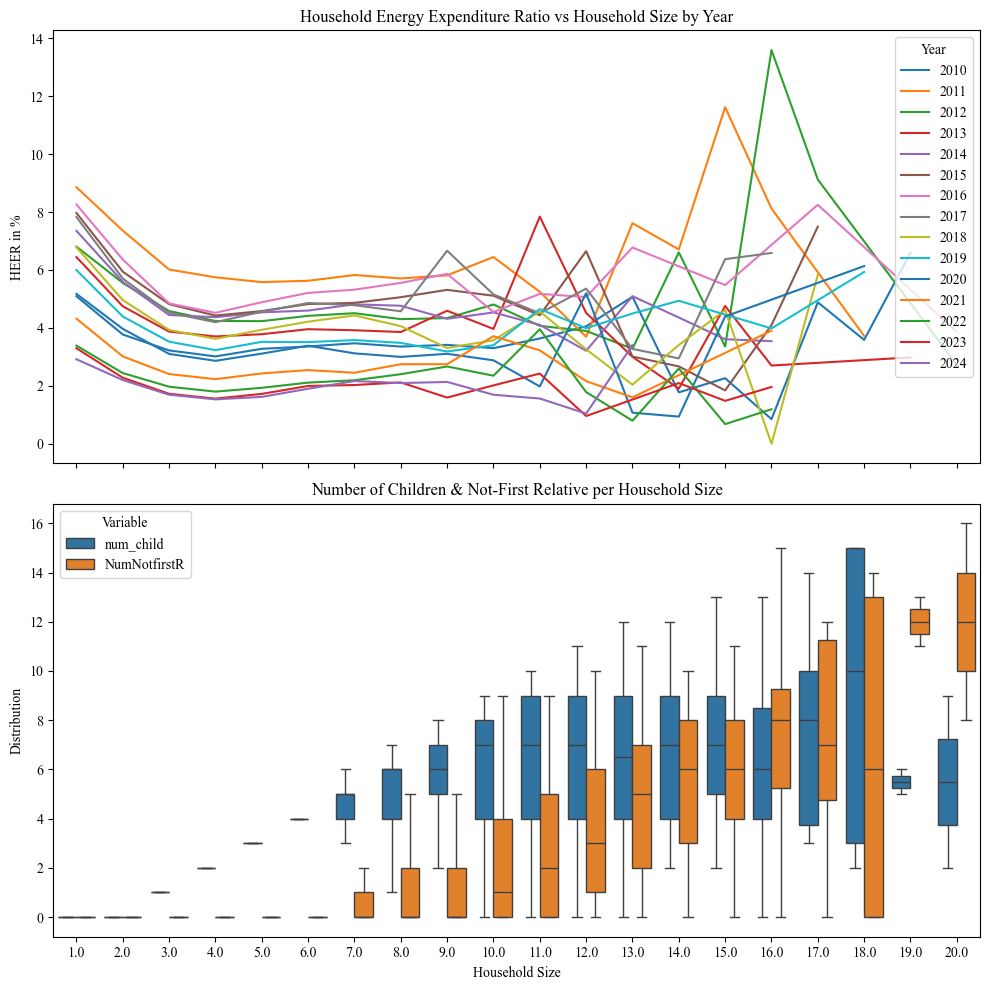

In [24]:
# --- Create two vertically stacked subplots ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# --- 1️⃣ Line plot: Energy Ratio vs Household Size ---
for year in range(2010, 2025):
    sns.lineplot(
        x = df_pivot["HHsize"]-1, 
        y = df_pivot[year], 
        label=str(year),
        ax = ax1
    )

ax1.set_xlabel("")  # Hide x-label (shared with second plot)
ax1.set_ylabel("HEER in %")
ax1.legend(title="Year")
ax1.set_title("Household Energy Expenditure Ratio vs Household Size by Year")

# --- 2️⃣ Boxplot: Children & Not-First Residents per Household Size ---
sns.boxplot(
    data=df_long,
    x="HHsize",
    y="Value",
    hue="Variable",
    showfliers=False,
    ax=ax2
)

ax2.set_xlabel("Household Size")
ax2.set_ylabel("Distribution")
ax2.set_title("Number of Children & Not-First Relative per Household Size")

plt.tight_layout()
plt.show()

<Axes: xlabel='HHsize', ylabel='number'>

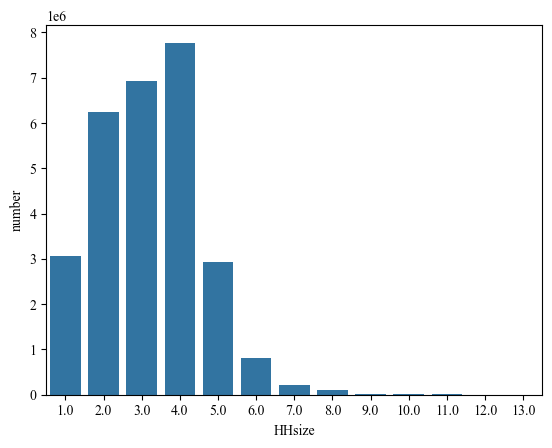

In [ ]:
# how many households we have in each household size group
df = data.groupby(['HHsize','year']).agg(
    year = ("year", "first"),
    HHsize = ("HHsize", "first"),
    number = ("weight", "sum")
).reset_index(drop = True)
df["number"] = df["number"].astype(int)
df = df[df["year"]==2024]
sns.barplot(
    x = df["HHsize"],
    y = df["number"]
)

In [43]:
all = df["number"].sum(axis=0)
lower_part = df[df["HHsize"]>6]["number"].sum(axis = 0)
print(f"the proportion of certain families is {round(lower_part/all,3)}")

the proportion of certain families is 0.013


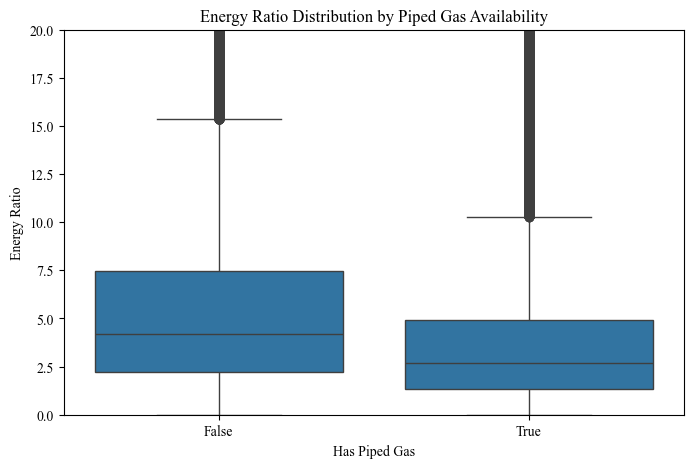

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=data,
    x="Pipegas",
    y="energy_Ratio"
)
plt.xlabel("Has Piped Gas")
plt.ylabel("Energy Ratio")
plt.ylim(0,20)
plt.title("Energy Ratio Distribution by Piped Gas Availability")
plt.show()


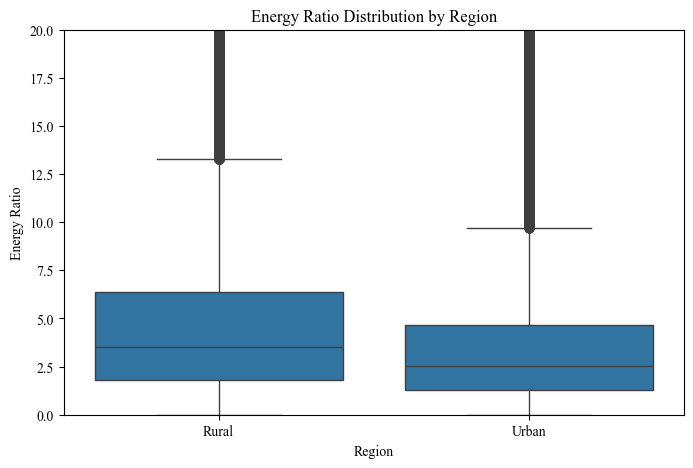

In [65]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=data,
    x="region",
    y="energy_Ratio"
)
plt.xlabel("Region")
plt.ylabel("Energy Ratio")
plt.ylim(0,20)
plt.title("Energy Ratio Distribution by Region")
plt.show()

In [11]:
cols = [
'Cookfuel',
'Heatfuel',
'Hotwaterfuel',
]
for col in cols:
    df = data.groupby([col, "Pipegas"]).size()
    print(df)

Cookfuel               Pipegas
Animal fuel            False          10
Diesel                 False         138
                       True            9
Electricity            False          58
                       True           91
Firewood and charcoal  False         595
                       True            7
LPG                    False      129361
                       True         2498
Natural gas            False        1454
                       True       434850
None                   False          56
                       True            2
Other fuels            False           2
                       True            1
White oil              False        1143
                       True           54
dtype: int64
Heatfuel               Pipegas
Animal fuel            False         124
                       True            1
Diesel                 False         502
                       True           34
Electricity            False       22719
                       

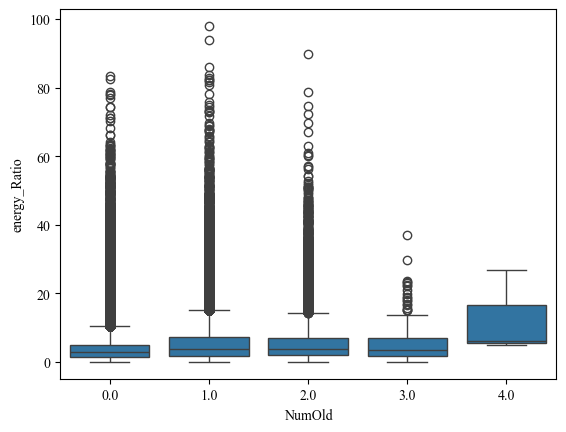

In [14]:
sns.boxplot(
    data = data,
    x = "NumOld",
    y = "energy_Ratio"
)
plt.show()

# Energy poverty calculation

In [3]:
data = pd.read_pickle("data.pkl")

In [4]:
data["Tenure"] = np.where(data["Tenure"].isin(['Owner', 'Other']), "Owner", "Renter")

In [34]:
data["Tenure"].unique()

array(['Owner', 'Renter'], dtype=object)

In [5]:
data["HHsizeRECLASS"] = np.where(
    data["HHsize"]<3, "couple", np.where(
        (data["HHsize"]>=3) & (data["HHsize"]<7), "withChildren", "large"
    )
)

In [6]:
data.groupby(["HHsizeRECLASS", "HHsize"]).agg(
    value = ("HHID", "count")
)

value
HHsizeRECLASS HHsize        
couple        1.00     44723
              2.00    103347
large         7.00     12308
              8.00      5234
              9.00      2088
              10.00      916
              11.00      405
              12.00      209
              13.00       98
              14.00       43
              15.00       31
              16.00       20
              17.00        8
              18.00        5
              19.00        2
              20.00        2
withChildren  3.00    133051
              4.00    156023
              5.00     80384
              6.00     31432

<Axes: xlabel='Tenure', ylabel='energy_Ratio'>

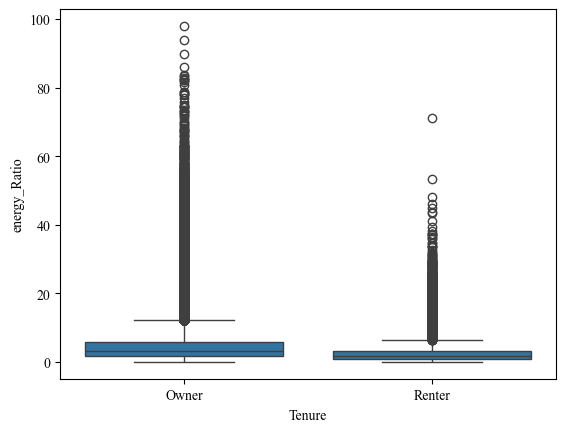

In [11]:
sns.boxplot(
    data = data,
    x = "Tenure",
    y = "energy_Ratio"
)

In [37]:
for q in data["quarter"].unique():
    df = data.loc[data["quarter"]==q]
    print(f"for quarter {q} the mean of energy ratio is {round(np.average(df['energy_Ratio'], weights=df['weight']),2)}")

for quarter spring the mean of energy ratio is 3.92
for quarter Summer the mean of energy ratio is 3.5
for quarter Fall the mean of energy ratio is 3.67
for quarter Winter the mean of energy ratio is 4.22


<Axes: xlabel='HeadWoman', ylabel='energy_Ratio'>

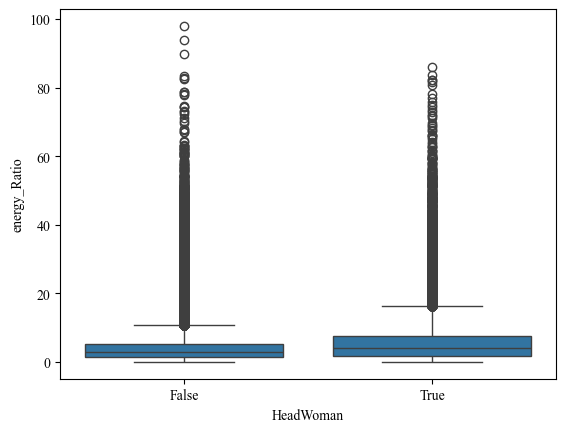

In [26]:
sns.boxplot(
    data = data,
    x = "HeadWoman",
    y = "energy_Ratio"
)

In [9]:
df = data.groupby(["Tenure", "HHsizeRECLASS", "region","year"]).agg(
number = ("HHID", "count")
).reset_index(drop = False)
df["unique"] = range(len(df))
df

,Tenure,HHsizeRECLASS,region,year,number,unique
0,Owner,couple,Rural,2010,3862,0
1,Owner,couple,Rural,2011,4105,1
2,Owner,couple,Rural,2012,4375,2
3,Owner,couple,Rural,2013,4399,3
4,Owner,couple,Rural,2014,4563,4
...,...,...,...,...,...,...
175,Renter,withChildren,Urban,2020,3069,175
176,Renter,withChildren,Urban,2021,3079,176
177,Renter,withChildren,Urban,2022,3020,177
178,Renter,withChildren,Urban,2023,2946,178


In [16]:
for year in df["year"].unique():
    df_year = df.loc[df["year"]==year]
    print(f"\n-------------------{year}-------------------\n\n")
    print(df_year["number"].describe())


-------------------2010-------------------


count      12.00
mean     3180.83
std      4290.56
min        58.00
25%       582.75
50%      1390.50
75%      3285.25
max     12912.00
Name: number, dtype: float64

-------------------2011-------------------


count      12.00
mean     3202.83
std      4304.59
min        74.00
25%       589.25
50%      1257.00
75%      3305.50
max     12914.00
Name: number, dtype: float64

-------------------2012-------------------


count      12.00
mean     3176.25
std      4309.42
min        56.00
25%       536.00
50%      1103.50
75%      3485.50
max     12849.00
Name: number, dtype: float64

-------------------2013-------------------


count      12.00
mean     3186.75
std      4358.46
min        41.00
25%       425.50
50%       949.50
75%      3568.00
max     13055.00
Name: number, dtype: float64

-------------------2014-------------------


count      12.00
mean     3182.42
std      4397.65
min        36.00
25%       367.00
50%       890.00
75%     

In [18]:
df["number"].mean()

np.float64(3168.4944444444445)

In [40]:
def weighted_mean(x):
    return np.average(x["energy_Ratio"], weights=x["weight"])

df = (
    data
    .groupby(["Tenure", "HHsizeRECLASS", "region","year"])
    .apply(weighted_mean)
    .reset_index(name="weighted_energy_ratio")
)

C:\Users\sinan\AppData\Local\Temp\ipykernel_10632\443735312.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(weighted_mean)


In [41]:
df

,Tenure,HHsizeRECLASS,region,year,weighted_energy_ratio
0,Owner,couple,Rural,2010,6.26
1,Owner,couple,Rural,2011,9.81
2,Owner,couple,Rural,2012,8.01
3,Owner,couple,Rural,2013,6.99
4,Owner,couple,Rural,2014,8.28
...,...,...,...,...,...
175,Renter,withChildren,Urban,2020,1.70
176,Renter,withChildren,Urban,2021,1.36
177,Renter,withChildren,Urban,2022,1.05
178,Renter,withChildren,Urban,2023,0.88


In [42]:
df[["weighted_energy_ratio"]].isna().sum()

weighted_energy_ratio    0
dtype: int64

In [43]:
df["2m"] = df["weighted_energy_ratio"]*2

In [44]:
data2 = pd.merge(data, df, on = ["Tenure", "HHsizeRECLASS", "region","year"], how = "left")
data2.shape[0] == data.shape[0]

True

In [45]:
data2["is_energyPoor"] = np.where(data2["energy_Ratio"]> data2["2m"], 1,0)

In [46]:
data2[["HHID","county_code","province_code","province","weight","is_energyPoor"]].head()

,HHID,county_code,province_code,province,weight,is_energyPoor
0,2000025066,0001,00,Markazi,153.79,0
1,2000077193,0006,00,Markazi,153.97,0
2,2000149068,0001,00,Markazi,140.70,0
3,2000125050,0010,00,Markazi,90.18,1
4,2000065114,0005,00,Markazi,196.92,0


In [47]:
data2.to_pickle("data2.pkl")

In [50]:
df = data2.groupby(["is_energyPoor","year"]).agg(
    num_HH = ("weight", "sum")
).reset_index(drop = False)
df = pd.pivot(data = df, index = "year", columns= "is_energyPoor", values= "num_HH")
df.reset_index(drop= False, inplace= True)
df.head()

is_energyPoor,year,0,1
0,2010,17545405.13,2488573.15
1,2011,18665215.73,2423373.64
2,2012,19425785.92,2289142.11
3,2013,20301199.80,2292880.61
4,2014,21067013.02,2260843.92


In [51]:
df.rename(columns= {
    0:"Not EnergyPoor",
    1:"EnergyPoor"
}, inplace = True)
df["pop_hh"] = df["Not EnergyPoor"]+ df["EnergyPoor"]
df["energy_ratio"] = 100*(df["EnergyPoor"]/df["pop_hh"])
print(df[["year","energy_ratio"]])

is_energyPoor  year  energy_ratio
0              2010         12.42
1              2011         11.49
2              2012         10.54
3              2013         10.15
4              2014          9.69
5              2015          9.09
6              2016          9.64
7              2017          9.65
8              2018          9.26
9              2019          9.33
10             2020          9.27
11             2021          9.15
12             2022          8.71
13             2023          9.25
14             2024          9.33


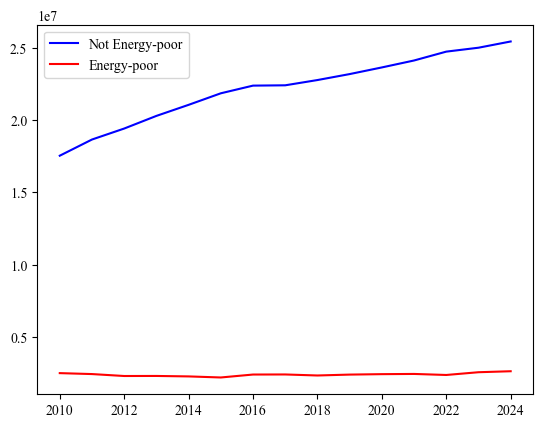

In [105]:
plt.plot(df["year"],df["Not EnergyPoor"], color = "blue", label = "Not Energy-poor")
plt.plot(df["year"], df["EnergyPoor"], color = "red", label = "Energy-poor")
plt.legend()
plt.show()

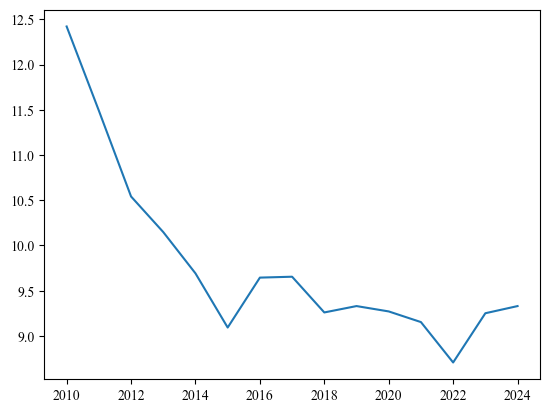

In [106]:
plt.plot(df["year"], df["energy_ratio"])
plt.show()

In [129]:
data2["energyPoor_HH"] = data2["weight"]*data2["is_energyPoor"]
province_df = data2.groupby(["year","province_code"]).agg(
    energyPoor_HH = ("energyPoor_HH", "sum"),
    HH = ("weight", "sum")
).reset_index(drop = False)
county_df = data2.groupby(["year","county_code"]).agg(
    energyPoor_HH = ("energyPoor_HH", "sum"),
    HH = ("weight", "sum")
).reset_index(drop = False)

province_df["energyPoorPer"] =100* (province_df["energyPoor_HH"]/province_df["HH"])
county_df["energyPoorPer"] =100* (county_df["energyPoor_HH"]/county_df["HH"])

print(province_df.head())
print(county_df.head())

   year province_code  energyPoor_HH         HH  energyPoorPer
0  2010            00       73477.83  418280.88          17.57
1  2010            01      122952.48  756945.78          16.24
2  2010            02      163197.73  883461.08          18.47
3  2010            03      119368.57 1041171.14          11.46
4  2010            04       87690.89  749082.53          11.71
   year county_code  energyPoor_HH        HH  energyPoorPer
0  2010        0001       30648.27 192256.15          15.94
1  2010        0002        2551.69   6415.33          39.77
2  2010        0003        4132.18  15964.97          25.88
3  2010        0004        6228.63  34168.61          18.23
4  2010        0005        2041.38  14539.28          14.04


In [130]:
for year in range(2010,2025):
    a = round(province_df.loc[province_df["year"]==year]["HH"].sum(),0)
    b = round(county_df.loc[county_df["year"]==year]["HH"].sum(),0)
    print(f"In {year}, the number of households is {a} and the sum of it in both datasets equal {a==b}")

In 2010, the number of households is 20033978.0 and the sum of it in both datasets equal True
In 2011, the number of households is 21088589.0 and the sum of it in both datasets equal True
In 2012, the number of households is 21714928.0 and the sum of it in both datasets equal True
In 2013, the number of households is 22594080.0 and the sum of it in both datasets equal True
In 2014, the number of households is 23327857.0 and the sum of it in both datasets equal True
In 2015, the number of households is 24053802.0 and the sum of it in both datasets equal True
In 2016, the number of households is 24789207.0 and the sum of it in both datasets equal True
In 2017, the number of households is 24815850.0 and the sum of it in both datasets equal True
In 2018, the number of households is 25109049.0 and the sum of it in both datasets equal True
In 2019, the number of households is 25584111.0 and the sum of it in both datasets equal True
In 2020, the number of households is 26074941.0 and the sum 

In [109]:
data2.head()

,HHID,month,household_type,region,quarter,weight,county_code,province_code,province,HHsize,...,energy_Ratio,climate,GeClimate,HHsizeRECLASS,quarter_Winter,NumOldRECLASS,weighted_energy_ratio,2m,is_energyPoor,energyPoor_HH
0,2000025066,1,NormalResiding,Rural,spring,153.79,0001,00,Markazi,7.00,...,6.81,Csa,C,large,0,someold,4.03,8.05,0,0.00
1,2000077193,2,NormalResiding,Rural,spring,153.97,0006,00,Markazi,6.00,...,4.47,Csa,C,withChildren,0,NoOld,4.47,8.95,0,0.00
2,2000149068,2,NormalResiding,Rural,spring,140.70,0001,00,Markazi,3.00,...,1.31,Csa,C,withChildren,0,NoOld,4.47,8.95,0,0.00
3,2000125050,2,NormalResiding,Rural,spring,90.18,0010,00,Markazi,5.00,...,10.62,Csa,C,withChildren,0,NoOld,4.47,8.95,1,90.18
4,2000065114,2,NormalResiding,Rural,spring,196.92,0005,00,Markazi,2.00,...,6.14,Csa,C,couple,0,someold,6.26,12.53,0,0.00


In [132]:
df = data2
df1 = pd.pivot_table(
    data=df,
    index="year",
    columns="region",
    values="energyPoor_HH",
    aggfunc="sum"
)
print(df1)

df2 = df.groupby(["year", "region"]).agg(
    year = ("year", "first"),
    region = ("region", "first"),
    total_HH = ("weight", "sum")
).reset_index(drop = True)
df2 = df2.pivot(index="year", columns= "region", values= "total_HH")
df2.rename(columns = {
    "Rural": "total_rural",
    "Urban": "total_urban"
}, inplace= True)
print(df2)

df3 = pd.merge(df1,df2, on = "year", how= "inner").reset_index(drop = False)
df3["urban_per"] = round((df3["Urban"]/df3["total_urban"])*100, 2)
df3["rural_per"] = round((df3["Rural"]/df3["total_rural"])*100, 2)
print(df3[["year", "urban_per", "rural_per"]])

region     Rural      Urban
year                       
2010   665828.86 1822744.29
2011   679862.41 1743511.23
2012   628222.18 1660919.93
2013   616924.90 1675955.72
2014   637331.19 1623512.73
2015   610002.16 1577153.80
2016   596081.87 1794780.96
2017   598652.00 1797218.00
2018   565996.00 1758988.00
2019   586763.23 1800243.68
2020   588621.21 1828723.97
2021   566833.00 1865194.00
2022   594903.75 1765573.86
2023   582915.69 1967861.23
2024   580824.00 2038503.00
region  total_rural  total_urban
year                            
2010     5326082.79  14707895.50
2011     5724770.90  15363818.47
2012     5613255.61  16101672.42
2013     5997312.64  16596767.77
2014     6124468.53  17203388.40
2015     6252856.42  17800945.99
2016     6386006.83  18403199.88
2017     6040157.00  18775693.00
2018     6063747.00  19045302.00
2019     6087730.72  19496379.81
2020     6083567.85  19991373.15
2021     6095028.00  20475675.00
2022     6110523.07  21001780.53
2023     6093751.77  21480063

# GIS ready process

In [111]:
print(province_df.shape)
print(province_df.shape[0]==31*15)
province_df.head()

(465, 5)
True


,year,province_code,energyPoor_HH,HH,energyPoorPer
0,2010,00,73477.83,418280.88,17.57
1,2010,01,122952.48,756945.78,16.24
2,2010,02,163197.73,883461.08,18.47
3,2010,03,119368.57,1041171.14,11.46
4,2010,04,87690.89,749082.53,11.71


In [112]:
print(county_df.shape, 429*15)
print(county_df.shape[0]==429*15)
county_df.head()

(5988, 5) 6435
False


,year,county_code,energyPoor_HH,HH,energyPoorPer
0,2010,0001,30648.27,192256.15,15.94
1,2010,0002,2551.69,6415.33,39.77
2,2010,0003,4132.18,15964.97,25.88
3,2010,0004,6228.63,34168.61,18.23
4,2010,0005,2041.38,14539.28,14.04


In [135]:
province_df2 = pd.pivot(data = province_df, index = "province_code", columns= "year", values = "energyPoorPer")
province_df2= province_df2.reset_index(drop= False)

In [136]:
county_df2 = pd.pivot(data = county_df, index = "county_code", columns= "year", values = "energyPoorPer")
county_df2 = county_df2.reset_index(drop = False)

In [145]:
province_gis= pd.read_excel("province_gis.xlsx", dtype={"province_code": str})
province_gis.head()

,Province_N,Province_E,Shape_Length,Shape_Area,province,province_code
0,قزوین,Qazvin,748134.08,15635402270.00,Qazvin,26
1,اردبیل,Ardebil,1042156.48,17999098261.19,Ardabil,24
2,زنجان,Zanjan,803819.87,21739889247.96,Zanjan,19
3,سمنان,Semnan,1561825.84,97141027649.25,Semnan,20
4,قم,Qom,517162.36,11474220549.16,Qom,25


In [151]:
county_gis= pd.read_excel("county_gis.xlsx", dtype={"county_code": str})
county_gis.head()

,OBJECTID,FARSI_NAM,Shape_Length,Shape_Area,county92,year,county_code,2010,2011,2012,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,1,بناب,152463.92,773733398.08,بناب,89,0312,16.15,41.06,23.11,...,26.23,23.78,13.53,24.39,18.73,10.28,10.26,16.01,3.69,10.20
1,2,خرم دره,131439.32,459803979.00,خرمدره,89,1907,5.82,17.03,10.32,...,6.78,6.11,8.92,10.47,19.75,18.67,11.70,8.96,4.49,1.74
2,3,بندرانزل,105607.47,300413135.03,بندرانزلي,89,0103,18.23,13.80,15.36,...,21.96,15.38,19.46,15.33,8.36,14.07,11.61,10.22,13.88,11.91
3,4,كنگاور,149412.98,888401265.99,کنگاور,89,0507,11.60,8.57,20.82,...,20.60,16.80,14.57,13.81,14.57,3.73,14.32,9.07,9.64,3.30
4,5,سرپل ذهاب,204215.96,902084203.20,سرپل ذهاب,89,0504,3.17,4.31,8.08,...,10.25,6.67,2.94,5.39,6.98,11.44,5.50,9.10,10.49,18.74


In [146]:
province_gis = pd.merge(province_gis, province_df2, on = "province_code", how = "left")

In [149]:
province_gis.isna().sum()

Province_N       0
Province_E       0
Shape_Length     0
Shape_Area       0
province         0
province_code    0
2010             0
2011             0
2012             0
2013             0
2014             0
2015             0
2016             0
2017             0
2018             0
2019             0
2020             0
2021             0
2022             0
2023             0
2024             0
dtype: int64

In [155]:
county_gis = county_gis.iloc[:, 0:7]

In [157]:
county_gis = pd.merge(county_gis, county_df2, on = "county_code", how = "left")

In [158]:
print(county_gis.isna().sum())

OBJECTID         0
FARSI_NAM        0
Shape_Length     0
Shape_Area       0
county92         0
year             0
county_code      1
2010            94
2011            94
2012            93
2013            32
2014            32
2015            32
2016            32
2017            32
2018             1
2019             1
2020             2
2021             1
2022             1
2023             1
2024             1
dtype: int64


In [159]:
county_gis.to_excel("county_gis.xlsx", index=False)
province_gis.to_excel("province_gis.xlsx", index=False)

# The data back from ArcGIS

In [167]:
county_gis= pd.read_excel("county_gis.xlsx", dtype={"county_code": str})
county_gis.drop(columns = ['year','Shape_Length','Shape_Area',"OBJECTID"], inplace = True)

In [168]:
county = pd.melt(frame= county_gis, id_vars=["FARSI_NAM","county92","county_code"], value_name= "energyPoorPer", var_name= "year")
county.head()

,FARSI_NAM,county92,county_code,year,energyPoorPer
0,بناب,بناب,0312,2010,18.79
1,خرم دره,خرمدره,1907,2010,5.71
2,بندرانزل,بندرانزلي,0103,2010,19.90
3,كنگاور,کنگاور,0507,2010,8.76
4,سرپل ذهاب,سرپل ذهاب,0504,2010,4.34


In [170]:
province_gis.drop(columns = ['Shape_Length','Shape_Area'], inplace = True)

In [172]:
province = pd.melt(frame = province_gis, id_vars=['Province_N', 'Province_E', 'province', 'province_code'], var_name="year", value_name="energyPoorPer")
province.head()

,Province_N,Province_E,province,province_code,year,energyPoorPer
0,قزوین,Qazvin,Qazvin,26,2010,8.21
1,اردبیل,Ardebil,Ardabil,24,2010,4.36
2,زنجان,Zanjan,Zanjan,19,2010,15.90
3,سمنان,Semnan,Semnan,20,2010,29.03
4,قم,Qom,Qom,25,2010,16.23


In [13]:
county = pd.read_excel("county_melt.xlsx", dtype={"county_code": str})
county = county.iloc[:, 1:]
print(county.shape)
county.head()

(6435, 5)


,FARSI_NAM,county92,county_code,year,energyPoorPer
0,بناب,بناب,0312,2010,18.79
1,خرم دره,خرمدره,1907,2010,5.71
2,بندرانزل,بندرانزلي,0103,2010,19.90
3,كنگاور,کنگاور,0507,2010,8.76
4,سرپل ذهاب,سرپل ذهاب,0504,2010,4.34


In [14]:
data = pd.read_pickle("data.pkl")
df = data.groupby(["year", "county_code"]).agg(
    num_HH = ("weight", "sum")
).reset_index(drop = False)
print(df.shape)
df.head()

(5988, 3)


,year,county_code,num_HH
0,2010,0001,192256.15
1,2010,0002,6415.33
2,2010,0003,15964.97
3,2010,0004,34168.61
4,2010,0005,14539.28


In [15]:
county = pd.merge(county, df, on = ["year", "county_code"], how = "left")

In [16]:
county.head()

,FARSI_NAM,county92,county_code,year,energyPoorPer,num_HH
0,بناب,بناب,0312,2010,18.79,36467.49
1,خرم دره,خرمدره,1907,2010,5.71,17865.33
2,بندرانزل,بندرانزلي,0103,2010,19.90,45070.15
3,كنگاور,کنگاور,0507,2010,8.76,22631.63
4,سرپل ذهاب,سرپل ذهاب,0504,2010,4.34,20295.18


In [23]:
import numpy as np

# --- Define Weighted Gini function (Mathematically identical to original when weights are equal) ---
def gini(array, weights):
    """Compute weighted Gini coefficient matching the exact discrete formula when weights are equal."""
    array = np.array(array, dtype=np.float64)
    weights = np.array(weights, dtype=np.float64)

    # remove NaN from both array and weights
    mask = ~np.isnan(array) & ~np.isnan(weights)
    array = array[mask]
    weights = weights[mask]

    n = len(array)
    if n == 0 or np.sum(array * weights) == 0:
        return np.nan

    # sort both by array values
    sort_idx = np.argsort(array)
    array = array[sort_idx]
    weights = weights[sort_idx]

    # cumulative sums
    cum_weights = np.cumsum(weights)
    
    # rank-weighted midpoint calculation matching discrete sample rank indexing
    midpoint_weights = cum_weights - (weights / 2.0)

    # generalized weighted formula matching: (2 * sum(rank * x) / (N * sum(x))) - (N + 1) / N
    return (2 * np.sum(midpoint_weights * array * weights)) / (cum_weights[-1] * np.sum(array * weights)) - 1.0


# --- Calculate Weighted Gini by year ---
gini_results_weighted = (
    county.groupby("year")
    .apply(lambda g: gini(g["energyPoorPer"], g["num_HH"]))
    .reset_index(name="Gini_Coefficient")
)

# --- Calculate Unweighted Gini (Pass identical weights to get EXACT original result) ---
gini_results_unweighted = (
    county.groupby("year")
    .apply(lambda g: gini(g["energyPoorPer"], np.ones(len(g))))
    .reset_index(name="Gini_Coefficient")
)
print(gini_results_weighted)
print(gini_results_unweighted)

    year  Gini_Coefficient
0   2010              0.27
1   2011              0.34
2   2012              0.31
3   2013              0.32
4   2014              0.38
5   2015              0.39
6   2016              0.41
7   2017              0.43
8   2018              0.43
9   2019              0.41
10  2020              0.43
11  2021              0.46
12  2022              0.46
13  2023              0.48
14  2024              0.46
    year  Gini_Coefficient
0   2010              0.36
1   2011              0.41
2   2012              0.39
3   2013              0.37
4   2014              0.39
5   2015              0.39
6   2016              0.41
7   2017              0.43
8   2018              0.43
9   2019              0.44
10  2020              0.44
11  2021              0.49
12  2022              0.49
13  2023              0.53
14  2024              0.54


C:\Users\sinan\AppData\Local\Temp\ipykernel_10632\1617199291.py:36: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: gini(g["energyPoorPer"], g["num_HH"]))
C:\Users\sinan\AppData\Local\Temp\ipykernel_10632\1617199291.py:43: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: gini(g["energyPoorPer"], np.ones(len(g))))


In [173]:
# --- Define Gini function ---
def gini(array):
    """Compute Gini coefficient of a numpy array."""
    array = np.array(array)
    array = array[~np.isnan(array)]  # remove NaN
    if len(array) == 0:
        return np.nan
    array = np.sort(array)
    n = len(array)
    cumvals = np.cumsum(array)
    return (2 * np.sum((np.arange(1, n + 1) * array)) / (n * np.sum(array))) - (n + 1) / n

# --- Calculate Gini by year ---
gini_results = (
    county.groupby("year")["energyPoorPer"]
    .apply(lambda x: gini(x))
    .reset_index(name="Gini_Coefficient")
)

print(gini_results)


    year  Gini_Coefficient
0   2010              0.36
1   2011              0.41
2   2012              0.39
3   2013              0.37
4   2014              0.39
5   2015              0.39
6   2016              0.41
7   2017              0.43
8   2018              0.43
9   2019              0.44
10  2020              0.44
11  2021              0.49
12  2022              0.49
13  2023              0.53
14  2024              0.54


In [175]:
for year in range(2018, 2025):
    df = county.loc[(county["year"]==year)& (county["energyPoorPer"].isna())]
    print(df)

     FARSI_NAM county92 county_code  year  energyPoorPer
3842   آغاجاري  آغاجاري         NaN  2018            NaN
     FARSI_NAM county92 county_code  year  energyPoorPer
4271   آغاجاري  آغاجاري         NaN  2019            NaN
     FARSI_NAM county92 county_code  year  energyPoorPer
4453   ابوموسي  ابوموسي        2201  2020            NaN
4700   آغاجاري  آغاجاري         NaN  2020            NaN
     FARSI_NAM county92 county_code  year  energyPoorPer
5129   آغاجاري  آغاجاري         NaN  2021            NaN
     FARSI_NAM county92 county_code  year  energyPoorPer
5558   آغاجاري  آغاجاري         NaN  2022            NaN
     FARSI_NAM county92 county_code  year  energyPoorPer
5987   آغاجاري  آغاجاري         NaN  2023            NaN
     FARSI_NAM county92 county_code  year  energyPoorPer
6416   آغاجاري  آغاجاري         NaN  2024            NaN


In [176]:
county.to_excel("county_melt.xlsx")
province.to_excel("province_melt.xlsx")

# Visualization of word table

In [4]:
from docx import Document
doc = Document(r"C:\Users\Mahsa\Desktop\energy poverty 04.11.2025.docx")

In [ ]:
'''
Document
 └── tables (list)
       ├── Table 0
       │     ├── rows (list)
       │     │     ├── Row 0
       │     │     │     ├── cells (list)
       │     │     │     │     ├── Cell 0 → text: "Header 1"
       │     │     │     │     └── Cell 1 → text: "Header 2"
       │     │     ├── Row 1
       │     │     │     ├── Cell 0 → text: "Value 1"
       │     │     │     └── Cell 1 → text: "Value 2"


'''


In [30]:
# Access the first table
table = doc.tables[1]

# Extract all rows and cells
data = []
for row in table.rows:
    row_data = [cell.text.strip() for cell in row.cells]
    data.append(row_data)

# Convert to DataFrame
df = pd.DataFrame(data)

# Optionally, use the first row as the header
df.columns = df.iloc[0]  # Set header
df = df[1:]
df.columns = df.columns.str.strip()
df["Year"] = df["Year"].astype("int") 
df["Moran’s I index"] = df["Moran’s I index"].astype("float64") 
df["Gini index"] = df["Gini index"].astype("float64") 
df.columns = df.columns.str.replace("’", "'", regex=False)
df

,Year,Moran's I index,Z_score,P_value,Gini index
1,2010,0.26,6.697242,0.000000,0.35
2,2011,0.33,8.553563,0.000000,0.41
3,2012,0.26,6.703694,0.000000,0.40
4,2013,0.33,10.090406,0.000000,0.37
5,2014,0.32,9.66685,0.000000,0.40
6,2015,0.24,7.34142,0.000000,0.39
7,2016,0.33,10.117062,0.000000,0.42
8,2017,0.31,9.352276,0.000000,0.44
9,2018,0.34,11.187461,0.000000,0.43
10,2019,0.28,9.375059,0.000000,0.45


In [37]:
df.to_pickle("docx_table.pkl")

In [26]:
gini = gini_results_weighted.loc[gini_results_weighted["year"] > 2012, "Gini_Coefficient"]
gini

3    0.32
4    0.38
5    0.39
6    0.41
7    0.43
8    0.43
9    0.41
10   0.43
11   0.46
12   0.46
13   0.48
14   0.46
Name: Gini_Coefficient, dtype: float64

In [29]:
gini = gini_results_weighted.loc[gini_results_weighted["year"] > 2012, "Gini_Coefficient"]
M1index = [
0.343276,0.316474,0.260397,0.274384,0.279240,0.335019,0.291499,0.361014,0.363162,0.328929,0.344604,0.330818
]
Year = list(range(2013, 2025))

df = pd.DataFrame({
    "Year": Year,
    "Gini": gini.values,
    "Moran's I": M1index
})
df.head(13)

,Year,Gini,Moran's I
0,2013,0.32,0.34
1,2014,0.38,0.32
2,2015,0.39,0.26
3,2016,0.41,0.27
4,2017,0.43,0.28
5,2018,0.43,0.34
6,2019,0.41,0.29
7,2020,0.43,0.36
8,2021,0.46,0.36
9,2022,0.46,0.33


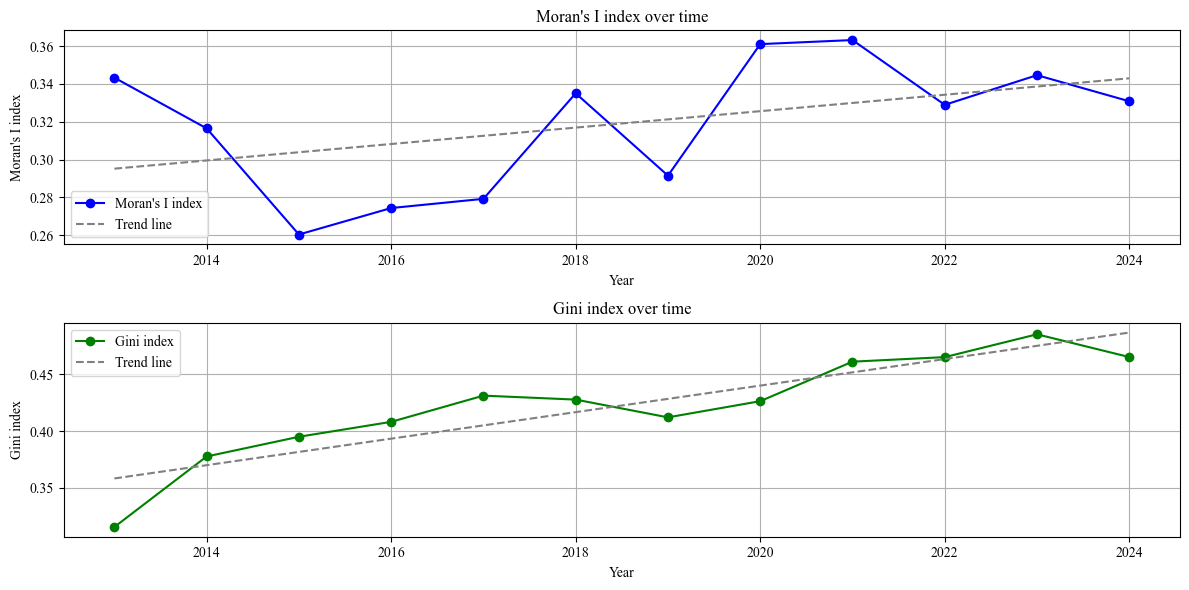

In [30]:
# Create subplots
fig, ax = plt.subplots(2, 1, figsize=(12, 6))

# ---------- 1️⃣ Moran's I index ----------
x = df["Year"]
y1 = df["Moran's I"]

# Plot data points
ax[0].plot(x, y1, marker='o', color='blue', label="Moran's I index")

# Calculate and plot trend line
z1 = np.polyfit(x, y1, 1)  # 1 = linear fit
p1 = np.poly1d(z1)
ax[0].plot(x, p1(x), "--", color="grey", label="Trend line")

# Labels and grid
ax[0].set_title("Moran's I index over time")
ax[0].set_xlabel("Year")
ax[0].set_ylabel("Moran's I index")
ax[0].legend()
ax[0].grid(True)


# ---------- 2️⃣ Gini index ----------
y2 = df["Gini"]

# Plot data points
ax[1].plot(x, y2, marker='o', color='green', label="Gini index")

# Calculate and plot trend line
z2 = np.polyfit(x, y2, 1)
p2 = np.poly1d(z2)
ax[1].plot(x, p2(x), "--", color="grey", label="Trend line")

# Labels and grid
ax[1].set_title("Gini index over time")
ax[1].set_xlabel("Year")
ax[1].set_ylabel("Gini index")
ax[1].legend()
ax[1].grid(True)

# Adjust layout and show
plt.tight_layout()
plt.show()

In [2]:
data = pd.read_pickle("data.pkl")
data.head()

,HHID,month,household_type,region,quarter,weight,county_code,province_code,province,HHsize,...,EducationExp,EducationSale,OtherExtraExp,OtherExtraSale,year,all_expenditure,all_energy_EXP,energy_Ratio,climate,GeClimate
0,2000025066,1,NormalResiding,Rural,spring,153.79,0001,00,Markazi,7.00,...,0.00,0.00,111726.33,0.00,2010,2085551.67,142000.00,6.81,Csa,C
1,2000077193,2,NormalResiding,Rural,spring,153.97,0006,00,Markazi,6.00,...,0.00,0.00,153169.00,0.00,2010,7162222.33,320000.00,4.47,Csa,C
2,2000149068,2,NormalResiding,Rural,spring,140.70,0001,00,Markazi,3.00,...,0.00,0.00,77513.67,0.00,2010,3056012.67,40000.00,1.31,Csa,C
3,2000125050,2,NormalResiding,Rural,spring,90.18,0010,00,Markazi,5.00,...,0.00,0.00,27500.00,0.00,2010,2071836.67,220000.00,10.62,Csa,C
4,2000065114,2,NormalResiding,Rural,spring,196.92,0005,00,Markazi,2.00,...,0.00,0.00,240398.00,0.00,2010,1383481.33,85000.00,6.14,Csa,C


In [13]:
df = data.groupby(["Pipegas", "year", "province"]).agg(
    num_HH = ("weight", "sum")
).reset_index(drop = False)
df = pd.pivot(data = df , index = ["year", "province"], columns = "Pipegas", values = "num_HH").reset_index(drop = False)
df.rename(columns = {
    False: "NotConnected",
    True: "Connected"
}, inplace = True)
df.head()


Pipegas,year,province,NotConnected,Connected
0,2010,Alborz,24958.99,628315.85
1,2010,Ardabil,71945.78,248613.31
2,2010,Bushehr,203255.35,13659.28
3,2010,Chaharmahal and Bakhtiari,24534.06,194573.47
4,2010,East Azerbaijan,89017.75,952153.39


In [24]:
df2 = data.groupby(["Pipegas", "year", "county_code"]).agg(
    num_HH = ("weight", "sum")
).reset_index(drop = False)
df2 = pd.pivot(data = df2 , index = ["year", "county_code"], columns = "Pipegas", values = "num_HH").reset_index(drop = False)
df2.rename(columns = {
    False: "NotConnected",
    True: "Connected"
}, inplace = True)
df2.head()

Pipegas,year,county_code,NotConnected,Connected
0,2010,0001,10976.76,181279.39
1,2010,0002,672.71,5742.62
2,2010,0003,4386.44,11578.53
3,2010,0004,6207.20,27961.41
4,2010,0005,2496.43,12042.85


In [18]:
df["total_HH"] = df["NotConnected"]+ df["Connected"]
df["share_connected"] = 100* (df["Connected"]/df["total_HH"])
df = df.loc[df["year"]==2024, ["province", "share_connected"]].sort_values("share_connected", ascending = False)

In [25]:
df2["total_HH"] = df2["NotConnected"]+ df2["Connected"]
df2["share_connected"] = 100* (df2["Connected"]/df2["total_HH"])
df2 = df2.loc[df2["year"]==2024, ["county_code", "share_connected"]].sort_values("share_connected", ascending = False)

In [29]:
df2

Pipegas,county_code,share_connected
5942,2501,99.92
5987,3006,99.89
5982,3001,99.89
5945,2603,99.88
5929,2319,99.81
...,...,...
5978,2908,NaN
5979,2909,NaN
5980,2910,NaN
5984,3003,NaN


In [20]:
province_gis = pd.read_excel("province_gis.xlsx", dtype={"province_code": str})
province_gis.drop(columns = ['Shape_Length','Shape_Area'], inplace = True)
province_gis.head()

,Province_N,Province_E,province,province_code,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,قزوین,Qazvin,Qazvin,26,8.21,14.29,8.13,9.70,9.41,8.21,7.64,6.05,4.29,4.55,1.90,2.11,1.63,1.26,0.40
1,اردبیل,Ardebil,Ardabil,24,4.36,7.79,7.04,6.59,7.63,8.22,9.01,6.86,6.34,8.66,7.15,10.82,8.78,6.36,5.41
2,زنجان,Zanjan,Zanjan,19,15.90,20.82,11.91,13.29,18.14,13.77,12.09,15.24,11.67,12.47,12.62,7.49,5.96,4.48,3.88
3,سمنان,Semnan,Semnan,20,29.03,30.05,29.01,13.75,12.58,11.97,12.12,12.46,14.21,10.44,15.23,7.57,5.99,6.63,4.94
4,قم,Qom,Qom,25,16.23,10.37,6.61,10.91,6.79,6.33,2.35,2.91,1.88,3.36,3.61,1.98,5.90,2.86,2.37


In [21]:
province_gis = pd.merge(province_gis, df, on = "province", how = "left")
province_gis

,Province_N,Province_E,province,province_code,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,share_connected
0,قزوین,Qazvin,Qazvin,26,8.21,14.29,8.13,9.70,9.41,8.21,7.64,6.05,4.29,4.55,1.90,2.11,1.63,1.26,0.40,99.78
1,اردبیل,Ardebil,Ardabil,24,4.36,7.79,7.04,6.59,7.63,8.22,9.01,6.86,6.34,8.66,7.15,10.82,8.78,6.36,5.41,99.95
2,زنجان,Zanjan,Zanjan,19,15.90,20.82,11.91,13.29,18.14,13.77,12.09,15.24,11.67,12.47,12.62,7.49,5.96,4.48,3.88,98.77
3,سمنان,Semnan,Semnan,20,29.03,30.05,29.01,13.75,12.58,11.97,12.12,12.46,14.21,10.44,15.23,7.57,5.99,6.63,4.94,98.55
4,قم,Qom,Qom,25,16.23,10.37,6.61,10.91,6.79,6.33,2.35,2.91,1.88,3.36,3.61,1.98,5.90,2.86,2.37,99.92
5,همدان,Hamedan,Hamadan,13,9.61,12.08,10.38,15.84,9.64,9.60,9.93,14.50,21.61,6.38,4.92,5.65,8.60,12.79,10.82,99.96
6,یزد,Yazd,Yazd,21,13.09,13.66,9.83,11.23,9.45,4.20,3.23,2.45,5.44,7.44,9.50,3.16,3.51,5.85,5.82,99.81
7,چهارمحال وبختیاری,Chaharmahal va Bakhtiyari,Chaharmahal and Bakhtiari,14,17.44,11.08,12.12,10.39,8.89,9.34,2.65,2.77,5.92,7.02,3.48,1.22,2.50,4.59,3.07,97.71
8,سیستان وبلوچستان,Sistan va Baluchestan,Sistan and Baluchestan,11,13.63,7.27,12.31,11.63,11.93,12.57,12.71,12.53,13.36,13.54,15.01,15.24,18.58,21.07,21.84,21.44
9,کردستان,Kordestan,Kurdistan,12,15.46,14.60,14.27,16.44,12.21,12.06,11.24,7.67,5.73,9.07,4.98,4.18,8.01,5.82,5.16,99.63


In [22]:
province_gis.to_excel("province_gis.xlsx")

# check the income data

In [1]:
import pyodbc

In [62]:
years = [1403]
for year in years:
    # Path to your .accdb file
    file_path = fr'C:\Users\sinan\Desktop\base\energy poverty\repo\HIES\HIES\raw_data\{year}\Outfile-{year}.accdb'
    # Connection string (for 64-bit Access Database Engine)
    conn_str = (
        r'DRIVER={Microsoft Access Driver (*.mdb, *.accdb)};'
        f'DBQ={file_path};'
    )
    # Connect
    conn = pyodbc.connect(conn_str)
    # List all table names
    tables = [table.table_name for table in conn.cursor().tables(tableType='TABLE')]
    print(f"Year is :{str(year)}".center(50))
    #---------------------------------------------------------------------------------
    Rdata1 = pd.read_sql(f"SELECT * FROM R{year}P4S01", conn)
    Udata1 = pd.read_sql(f"select * from U{year}P4S01", conn)
    data1 = pd.concat([Rdata1, Udata1], axis=0)
    Rdata2 = pd.read_sql(f"SELECT * FROM R{year}P4S02", conn)
    Udata2 = pd.read_sql(f"select * from U{year}P4S02", conn)
    data2 = pd.concat([Rdata2, Udata2], axis=0)

    data1.rename(columns = {
        "Address" : "HHID",
        "DYCOL15": "IncomeLastYear"
    }, inplace=True)
    data1 = data1.loc[:, ["HHID", "IncomeLastYear"]]
    data1["HHID"] = data1["HHID"].astype(str)
    data1["IncomeLastYear"] = data1["IncomeLastYear"].astype(float)
    data1 = data1.groupby("HHID").agg(
    IncomeLastYear = ("IncomeLastYear", "sum")
    ).reset_index(drop = False)
    data1 = data1[data1["IncomeLastYear"]>0]


    data2.rename(columns = {
        "Address" : "HHID",
        "DYCOL15": "IncomeLastYear"
    }, inplace=True)
    data2 = data2.loc[:, ["HHID", "IncomeLastYear"]]
    data2["HHID"] = data2["HHID"].astype(str)
    data2["IncomeLastYear"] = pd.to_numeric(data2["IncomeLastYear"], errors='coerce')
    data2 = data2.groupby("HHID").agg(
    IncomeLastYear = ("IncomeLastYear", "sum")
    ).reset_index(drop = False)
    data2 = data2[data2["IncomeLastYear"]>0]

                  Year is :1403                   


C:\Users\sinan\AppData\Local\Temp\ipykernel_26728\4234865602.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  Rdata1 = pd.read_sql(f"SELECT * FROM R{year}P4S01", conn)
C:\Users\sinan\AppData\Local\Temp\ipykernel_26728\4234865602.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  Udata1 = pd.read_sql(f"select * from U{year}P4S01", conn)
C:\Users\sinan\AppData\Local\Temp\ipykernel_26728\4234865602.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  Rdata2 = pd.read_sql(f"SELECT * FROM R{year}P4S02", conn)
C:\Users\sina

In [53]:
data1

,HHID,IncomeLastYear
0,10001000142,2043200000.00
1,10001000147,540000000.00
2,10001000148,1100000000.00
3,10001000150,2100000008.00
4,10001000253,1909800004.00
...,...,...
17690,23006709653,1920000000.00
17691,23006709742,1450000000.00
17692,23006709750,1806000000.00
17693,23006709753,4140000000.00


In [54]:
data2

,HHID,IncomeLastYear
0,10001000147,6527000000.00
1,10001000153,2040000000.00
2,10001000246,3700000000.00
3,10001000440,1585000000.00
4,10001000450,1200000000.00
...,...,...
11918,23006709640,2240000000.00
11919,23006709647,2500000000.00
11920,23006709837,2400000000.00
11921,23006709841,2800000000.00


In [55]:
17688 + 11788 

29476

In [63]:
df1_merge = pd.merge(data1, data2, on = "HHID", how = "inner", suffixes=('_K', '_A'))
df1_merge

,HHID,IncomeLastYear_K,IncomeLastYear_A
0,10001000147,540000000.00,6527000000.00
1,10001000450,320000000.00,1200000000.00
2,10001000750,300000000.00,1300000000.00
3,10001000950,2024804000.00,600000000.00
4,10001001143,380000000.00,960000000.00
...,...,...,...
2996,23005707353,2387999998.00,1440000000.00
2997,23005707541,1194000000.00,1800000000.00
2998,23005707744,1407400000.00,3000000000.00
2999,23006708644,2150000000.00,120000000.00


In [64]:
df1_merge["total_income"] = df1_merge["IncomeLastYear_K"] + df1_merge["IncomeLastYear_A"]
df1_merge = df1_merge[[ "HHID", "total_income"]]
df1_merge["total_income"].describe()

count           3001.00
mean      2607799336.91
std       4102551734.12
min        200000000.00
25%       1362000000.00
50%       2080000000.00
75%       3085000000.00
max     154210000000.00
Name: total_income, dtype: float64

In [58]:
2060000000.0/120000000

17.166666666666668

In [67]:
29476 - 3001

26475

In [77]:
df2_merge = pd.merge(data1, data2, on = "HHID", how = "outer")
df2_merge.rename(columns = {
    "IncomeLastYear_x": "IncomeLastYear_K",
    "IncomeLastYear_y": "IncomeLastYear_A"
}, inplace = True)
df2_merge.fillna(0, inplace = True)
df_merge = pd.merge(df2_merge, df1_merge, on = "HHID", how = "left")
df_merge.shape[0] == 26475

True

In [78]:
df_merge["total_income"] = df_merge["IncomeLastYear_K"] + df_merge["IncomeLastYear_A"]
df_merge = df_merge[["HHID", "total_income"]]
df_merge["monthly_income"] = df_merge["total_income"]/12
df_merge.head()

,HHID,total_income,monthly_income
0,10001000142,2043200000.00,170266666.67
1,10001000147,7067000000.00,588916666.67
2,10001000148,1100000000.00,91666666.67
3,10001000150,2100000008.00,175000000.67
4,10001000153,2040000000.00,170000000.00


In [79]:
df_merge["monthly_income"].describe()

count         26475.00
mean      149956504.20
std       161591546.98
min          416666.67
25%        80000000.00
50%       125000000.00
75%       182916666.67
max     12850833333.33
Name: monthly_income, dtype: float64

In [80]:
df_merge.to_pickle("income1403.pkl")

In [88]:
data = pd.read_pickle("data.pkl")

In [89]:
data = data.loc[data["year"] == 2024, ["HHID", "all_expenditure"]]
print(data.shape)
data.head()

(37343, 2)


,HHID,all_expenditure
545038,20102398853,6088000.00
545039,22405644553,94132000.00
545040,22704667446,165614666.67
545041,21406550753,114624128.00
545042,20922499847,163495666.67


In [90]:
# the number of observations missing in the income dataset
37343 - 26475

10868

In [101]:
df_in_ex = pd.merge(data, df_merge, on = "HHID", how = "outer")
print(df_in_ex.shape)
df_in_ex.head(10)

(37352, 4)


,HHID,all_expenditure,total_income,monthly_income
0,10001000142,315144166.67,2043200000.00,170266666.67
1,10001000147,341654333.33,7067000000.00,588916666.67
2,10001000148,402012166.67,1100000000.00,91666666.67
3,10001000150,447587333.33,2100000008.00,175000000.67
4,10001000153,317236666.67,2040000000.00,170000000.00
5,10001000238,98272000.00,NaN,NaN
6,10001000240,126282500.00,NaN,NaN
7,10001000243,119080833.33,NaN,NaN
8,10001000246,457271333.33,3700000000.00,308333333.33
9,10001000250,81845833.33,NaN,NaN


In [92]:
df_in_ex.isna().sum()

HHID                   0
all_expenditure        9
total_income       10877
monthly_income     10877
dtype: int64

Some of the samples included in the 37343 observations had already been excluded from the income calculation, primarily due to invalid income values (9)
Some of the samples included in the 26475 observations had already been excluded from the expenditure calculation, primarily due to 0 food expenditures (9)

In [108]:
df_in_ex.dropna(inplace = True)
df_in_ex.shape[0] == 37352 - 9 - 10877

True

In [111]:
df_in_ex["income_expenditure"] = (df_in_ex["monthly_income"]-df_in_ex["all_expenditure"])/10000000
df_in_ex["income_expenditure"].describe()

count   26466.00
mean        0.58
std        16.16
min      -503.21
25%        -3.74
50%         0.69
75%         4.93
max      1049.64
Name: income_expenditure, dtype: float64

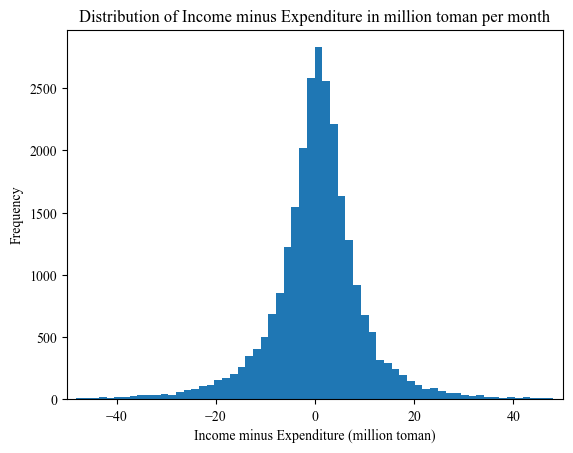

In [118]:
plt.hist(df_in_ex["income_expenditure"], bins=1000)
plt.title("Distribution of Income minus Expenditure in million toman per month")
plt.xlabel("Income minus Expenditure (million toman)")
plt.xlim(-50, 50)
plt.ylabel("Frequency")
plt.show()


# Comparing the energy-poor households


In [6]:
data2 = pd.read_pickle("data2.pkl")

In [ ]:
data

['HHID',
 'month',
 'household_type',
 'region',
 'quarter',
 'weight',
 'county_code',
 'province_code',
 'province',
 'HHsize',
 'AveAge',
 'NumChild_U5',
 'NumChild_B5_7',
 'NumChild_B7_18',
 'NumChildOver18',
 'HeadWoman',
 'Dep_Student',
 'Num_Literate',
 'NumSpouse',
 'NumEmployed',
 'NumOld',
 'NumMale',
 'NumNotfirstR',
 'Tenure',
 'Room',
 'Area',
 'Skeleton',
 'MainMaterial',
 'PrivateVehicle',
 'Motorcycle',
 'Bike',
 'Radio',
 'Cassette',
 'TVbw',
 'TV',
 'VideoPlayer',
 'Computer',
 'Cellphone',
 'Freezer',
 'Refrigerator',
 'Freez_refrig',
 'Vacuum',
 'Washer',
 'Sewing',
 'Fan',
 'Cooler_water_portable',
 'Cooler_gas_portable',
 'Dishwasher',
 'None',
 'Pipewater',
 'Electricity',
 'Pipegas',
 'Phone',
 'Internet',
 'Bathroom',
 'Kitchen',
 'Cooler_water',
 'Centralcooler',
 'Centralheat',
 'Pakage',
 'Cooler_gas',
 'Sewer_network',
 'Cookfuel',
 'Heatfuel',
 'Hotwaterfuel',
 'FoodExp',
 'CigarExp',
 'NonCatDrinksExp',
 'ClothExp',
 'InvestExp',
 'FurnitureExp',
 'Medica

In [42]:
df= data2.groupby(["year", "is_energyPoor"]).agg(
    amusement_mean = ("AmusementExp", "mean"),
    restaurant_mean = ("RestaurantExp", "mean"),
    food_mean = ("FoodExp", "mean"),
    cloth_mean = ("ClothExp", "mean"),
    hotel_mean = ("HotelExp", "mean"),
    invest_mean = ("InvestExp", "mean"),
).reset_index(drop = False)
df = pd.pivot(data = df, index = "year", columns = "is_energyPoor", values = ["amusement_mean"]).reset_index(drop = False)
df.columns = df.columns.get_level_values(1)
df.rename(columns = {
    "": "year",
    0: "Not Energy Poor",
    1: "Energy Poor"
}, inplace = True)
df["per"] = round(df["Not Energy Poor"]/(df["Energy Poor"]),1)
df["per"].describe()

count   15.00
mean     2.69
std      0.42
min      2.20
25%      2.35
50%      2.70
75%      3.00
max      3.50
Name: per, dtype: float64

In [43]:
df= data2.groupby(["year", "is_energyPoor"]).agg(
    amusement_mean = ("AmusementExp", "mean"),
    restaurant_mean = ("RestaurantExp", "mean"),
    food_mean = ("FoodExp", "mean"),
    cloth_mean = ("ClothExp", "mean"),
    hotel_mean = ("HotelExp", "mean"),
    invest_mean = ("InvestExp", "mean"),
).reset_index(drop = False)
df = pd.pivot(data = df, index = "year", columns = "is_energyPoor", values = ["restaurant_mean"]).reset_index(drop = False)
df.columns = df.columns.get_level_values(1)
df.rename(columns = {
    "": "year",
    0: "Not Energy Poor",
    1: "Energy Poor"
}, inplace = True)
df["per"] = round(df["Not Energy Poor"]/(df["Energy Poor"]),1)
df["per"].describe()

count   15.00
mean     3.08
std      0.66
min      2.00
25%      2.55
50%      3.00
75%      3.70
max      4.00
Name: per, dtype: float64

In [44]:
df= data2.groupby(["year", "is_energyPoor"]).agg(
    amusement_mean = ("AmusementExp", "mean"),
    restaurant_mean = ("RestaurantExp", "mean"),
    food_mean = ("FoodExp", "mean"),
    cloth_mean = ("ClothExp", "mean"),
    hotel_mean = ("HotelExp", "mean"),
    invest_mean = ("InvestExp", "mean"),
).reset_index(drop = False)
df = pd.pivot(data = df, index = "year", columns = "is_energyPoor", values = ["food_mean"]).reset_index(drop = False)
df.columns = df.columns.get_level_values(1)
df.rename(columns = {
    "": "year",
    0: "Not Energy Poor",
    1: "Energy Poor"
}, inplace = True)
df["per"] = round(df["Not Energy Poor"]/(df["Energy Poor"]),1)
df["per"].describe()

count   15.00
mean     1.59
std      0.15
min      1.30
25%      1.50
50%      1.60
75%      1.70
max      1.80
Name: per, dtype: float64

In [45]:
df= data2.groupby(["year", "is_energyPoor"]).agg(
    amusement_mean = ("AmusementExp", "mean"),
    restaurant_mean = ("RestaurantExp", "mean"),
    food_mean = ("FoodExp", "mean"),
    cloth_mean = ("ClothExp", "mean"),
    hotel_mean = ("HotelExp", "mean"),
    invest_mean = ("InvestExp", "mean"),
).reset_index(drop = False)
df = pd.pivot(data = df, index = "year", columns = "is_energyPoor", values = ["cloth_mean"]).reset_index(drop = False)
df.columns = df.columns.get_level_values(1)
df.rename(columns = {
    "": "year",
    0: "Not Energy Poor",
    1: "Energy Poor"
}, inplace = True)
df["per"] = round(df["Not Energy Poor"]/(df["Energy Poor"]),1)
df["per"].describe()

count   15.00
mean     3.21
std      0.84
min      1.40
25%      2.65
50%      3.40
75%      3.80
max      4.40
Name: per, dtype: float64

In [50]:
df= data2.groupby(["year", "is_energyPoor"]).agg(
    amusement_mean = ("AmusementExp", "mean"),
    restaurant_mean = ("RestaurantExp", "mean"),
    food_mean = ("FoodExp", "mean"),
    cloth_mean = ("ClothExp", "mean"),
    hotel_mean = ("HotelExp", "mean"),
    invest_mean = ("InvestExp", "mean"),
).reset_index(drop = False)
df = pd.pivot(data = df, index = "year", columns = "is_energyPoor", values = ["hotel_mean"]).reset_index(drop = False)
df.columns = df.columns.get_level_values(1)
df.rename(columns = {
    "": "year",
    0: "Not Energy Poor",
    1: "Energy Poor"
}, inplace = True)
df["per"] = round(df["Not Energy Poor"]/(df["Energy Poor"]),1)
print(df)
df[df["year"]!= 2023]["per"].describe()

is_energyPoor  year  Not Energy Poor  Energy Poor   per
0              2010         14018.60      1357.19 10.30
1              2011         17281.29      1018.46 17.00
2              2012         21811.09      2843.95  7.70
3              2013         20193.95      2911.36  6.90
4              2014         48453.48      1347.59 36.00
5              2015         33632.21      2381.46 14.10
6              2016         52478.32      5249.93 10.00
7              2017         55361.08      3026.50 18.30
8              2018         75690.36      2365.25 32.00
9              2019         55655.17      1406.90 39.60
10             2020          8938.50       693.26 12.90
11             2021         23324.11       571.27 40.80
12             2022        121085.39     27116.40  4.50
13             2023        160963.24         0.00   inf
14             2024        282100.55      3648.48 77.30


count   14.00
mean    23.39
std     19.99
min      4.50
25%     10.07
50%     15.55
75%     35.00
max     77.30
Name: per, dtype: float64

In [52]:
df= data2.groupby(["year", "is_energyPoor"]).agg(
    amusement_mean = ("AmusementExp", "mean"),
    restaurant_mean = ("RestaurantExp", "mean"),
    food_mean = ("FoodExp", "mean"),
    cloth_mean = ("ClothExp", "mean"),
    hotel_mean = ("HotelExp", "mean"),
    invest_mean = ("InvestExp", "mean"),
).reset_index(drop = False)
df = pd.pivot(data = df, index = "year", columns = "is_energyPoor", values = ["invest_mean"]).reset_index(drop = False)
df.columns = df.columns.get_level_values(1)
df.rename(columns = {
    "": "year",
    0: "Not Energy Poor",
    1: "Energy Poor"
}, inplace = True)
df["per"] = round(df["Not Energy Poor"]/(df["Energy Poor"]),1)
df["per"].describe()

count   15.00
mean     1.87
std      0.56
min      1.10
25%      1.50
50%      1.80
75%      2.25
max      3.10
Name: per, dtype: float64